# FinQA exploratory data analysis

This M2 notebook audits the downloaded official FinQA public splits. It investigates structure, quality, question and context characteristics, programs, evidence annotations, and split diagnostics. This is exploratory analysis, not model evaluation: test labels, programs, and gold evidence are not used for training or model selection.

In [1]:
import hashlib
import json
import os
import re
import tempfile
from collections import Counter
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from finevidence.data import load_finqa_split

SEED = 42
SPLIT_NAMES = ("train", "dev", "test")
current_directory = Path.cwd().resolve()
PROJECT_ROOT = (
    current_directory.parent if current_directory.name == "notebooks" else current_directory
)
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

pd.set_option("display.max_colwidth", 120)
print({"raw_data_dir": str(RAW_DATA_DIR.relative_to(PROJECT_ROOT)), "seed": SEED})

{'raw_data_dir': 'data/raw', 'seed': 42}


## Load and validate the official splits

The loader verifies only the observed top-level contract: each file must parse to a JSON list of object records. Field-level checks follow below so this notebook does not assume an unverified schema.

## Download or verify the official public splits

This notebook is the only acquisition workflow. It uses commit-pinned URLs from the official FinQA repository, downloads only missing public `train`, `dev`, and `test` files, validates JSON before finalizing a new file, and refuses to overwrite an existing raw file. `private_test.json` is deliberately excluded.

In [2]:
FINQA_REVISION = "0f16e2867befa6840783e58be38c9efb9229d742"
FINQA_REPOSITORY = "https://github.com/czyssrs/FinQA"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)


def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


download_rows = []
for split_name in SPLIT_NAMES:
    destination = RAW_DATA_DIR / f"{split_name}.json"
    source_url = (
        "https://raw.githubusercontent.com/czyssrs/FinQA/"
        f"{FINQA_REVISION}/dataset/{split_name}.json"
    )
    if destination.exists():
        with destination.open(encoding="utf-8") as file:
            payload = json.load(file)
        state = "existing; verified, not overwritten"
    else:
        with tempfile.NamedTemporaryFile(
            dir=RAW_DATA_DIR, prefix=f".{split_name}.", delete=False
        ) as temporary_file:
            temporary_path = Path(temporary_file.name)
            try:
                with urlopen(source_url) as response:
                    while chunk := response.read(1024 * 1024):
                        temporary_file.write(chunk)
                with temporary_path.open(encoding="utf-8") as file:
                    payload = json.load(file)
                if not isinstance(payload, list):
                    raise ValueError(f"Expected a JSON list from {source_url}.")
                if destination.exists():
                    raise FileExistsError(f"Refusing to overwrite {destination}.")
                os.replace(temporary_path, destination)
                state = "downloaded and JSON-validated"
            except Exception:
                temporary_path.unlink(missing_ok=True)
                raise
    if not isinstance(payload, list):
        raise ValueError(f"Expected a JSON list in {destination}.")
    download_rows.append(
        {
            "split": split_name,
            "status": state,
            "records": len(payload),
            "bytes": destination.stat().st_size,
            "sha256": file_sha256(destination),
            "source_url": source_url,
        }
    )

download_manifest = pd.DataFrame(download_rows).set_index("split")
display(download_manifest)

,status,records,bytes,sha256,source_url
split,,,,,
train,"existing; verified, not overwritten",6251,78216616,49f237eb9779b569473b26b08048867d04635a7cc39ad6a7a5664c55bb428db6,https://raw.githubusercontent.com/czyssrs/FinQA/0f16e2867befa6840783e58be38c9efb9229d742/dataset/train.json
dev,"existing; verified, not overwritten",883,10954658,a847fb7e0d61a3125a1e2909852df6b89f1ee64d2c5ff1bf689e332214deee51,https://raw.githubusercontent.com/czyssrs/FinQA/0f16e2867befa6840783e58be38c9efb9229d742/dataset/dev.json
test,"existing; verified, not overwritten",1147,14395143,831dbfb2e785dbc227f895ce3f24046433467aec67b09db2bd6ac7692a8a30dc,https://raw.githubusercontent.com/czyssrs/FinQA/0f16e2867befa6840783e58be38c9efb9229d742/dataset/test.json


In [3]:
split_paths = {name: RAW_DATA_DIR / f"{name}.json" for name in SPLIT_NAMES}
missing_paths = [path for path in split_paths.values() if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f"Missing FinQA split files: {missing_paths}")

splits = {name: load_finqa_split(path) for name, path in split_paths.items()}
split_overview = pd.DataFrame(
    [
        {
            "split": name,
            "records": len(records),
            "top_level_type": type(records).__name__,
            "first_record_type": type(records[0]).__name__,
        }
        for name, records in splits.items()
    ]
).set_index("split")
display(split_overview)

first_example = splits["train"][0]
compact_preview = {
    "id": first_example.get("id"),
    "filename": first_example.get("filename"),
    "top_level_keys": sorted(first_example),
    "qa_keys": sorted(first_example.get("qa", {})),
    "table_rows": len(first_example.get("table", [])),
    "pre_text_lines": len(first_example.get("pre_text", [])),
    "post_text_lines": len(first_example.get("post_text", [])),
}
compact_preview

,records,top_level_type,first_record_type
split,,,
train,6251,list,dict
dev,883,list,dict
test,1147,list,dict


{'id': 'ADI/2009/page_49.pdf-1',
 'filename': 'ADI/2009/page_49.pdf',
 'top_level_keys': ['filename',
  'id',
  'post_text',
  'pre_text',
  'qa',
  'table',
  'table_ori',
  'table_retrieved',
  'table_retrieved_all',
  'text_retrieved',
  'text_retrieved_all'],
 'qa_keys': ['ann_table_rows',
  'ann_text_rows',
  'answer',
  'exe_ans',
  'explanation',
  'gold_inds',
  'model_input',
  'program',
  'program_re',
  'question',
  'steps',
  'tfidftopn'],
 'table_rows': 4,
 'pre_text_lines': 15,
 'post_text_lines': 35}

## Observed schema

This checks the keys and runtime value types actually present in every record. Differences across official splits would affect loader and preprocessing design.

In [4]:
def keys_in_records(records, field=None):
    if field is None:
        return set().union(*(record.keys() for record in records))
    return set().union(*(record[field].keys() for record in records))


top_level_keys = {name: keys_in_records(records) for name, records in splits.items()}
qa_keys = {name: keys_in_records(records, "qa") for name, records in splits.items()}

schema_rows = []
for name, records in splits.items():
    for field in sorted(top_level_keys[name]):
        values = [record.get(field) for record in records]
        schema_rows.append(
            {
                "split": name,
                "level": "record",
                "field": field,
                "types": ", ".join(sorted({type(value).__name__ for value in values})),
                "missing": sum(field not in record for record in records),
            }
        )
    for field in sorted(qa_keys[name]):
        values = [record["qa"].get(field) for record in records]
        schema_rows.append(
            {
                "split": name,
                "level": "qa",
                "field": field,
                "types": ", ".join(sorted({type(value).__name__ for value in values})),
                "missing": sum(field not in record["qa"] for record in records),
            }
        )

schema_frame = pd.DataFrame(schema_rows)
display(schema_frame.pivot(index=["level", "field"], columns="split", values="types"))
print(
    "Top-level keys identical across splits:",
    len(set(map(frozenset, top_level_keys.values()))) == 1,
)
print("QA keys identical across splits:", len(set(map(frozenset, qa_keys.values()))) == 1)
display(schema_frame.groupby(["level", "field"])["missing"].sum().to_frame())

split                              dev        test       train
level  field                                                  
qa     ann_table_rows             list        list        list
       ann_text_rows              list        list        list
       answer                      str         str         str
       exe_ans              float, str  float, str  float, str
       explanation                 str         str         str
       gold_inds                  dict        dict        dict
       model_input                list        list        list
       program                     str         str         str
       program_re                  str         str         str
       question                    str         str         str
       steps                      list        list        list
       tfidftopn                  dict        dict        dict
record filename                    str         str         str
       id                          str         str         str
       post_text                  list        list        list
       pre_text                   list        list        list
       qa                         dict        dict        dict
       table                      list        list        list
       table_ori                  list        list        list
       table_retrieved            list        list        list
       table_retrieved_all        list        list        list
       text_retrieved             list        list        list
       text_retrieved_all         list        list        list

Top-level keys identical across splits: True
QA keys identical across splits: True


missing
level  field                       
qa     ann_table_rows             0
       ann_text_rows              0
       answer                     0
       exe_ans                    0
       explanation                0
       gold_inds                  0
       model_input                0
       program                    0
       program_re                 0
       question                   0
       steps                      0
       tfidftopn                  0
record filename                   0
       id                         0
       post_text                  0
       pre_text                   0
       qa                         0
       table                      0
       table_ori                  0
       table_retrieved            0
       table_retrieved_all        0
       text_retrieved             0
       text_retrieved_all         0

## Data-quality and split-integrity checks

The following diagnostics preserve the publisher's assignments. They surface issues for handling decisions; they do not drop records or establish leakage on their own.

In [5]:
def is_empty(value):
    return value is None or value == "" or value == [] or value == {}


quality_rows = []
for name, records in splits.items():
    table_rows = [len(record["table"]) for record in records]
    table_widths = [len(record["table"][0]) for record in records]
    irregular_tables = sum(len({len(row) for row in record["table"]}) != 1 for record in records)
    quality_rows.extend(
        [
            {"split": name, "check": "empty id", "count": sum(is_empty(r["id"]) for r in records)},
            {
                "split": name,
                "check": "duplicate IDs within split",
                "count": len(records) - len({r["id"] for r in records}),
            },
            {
                "split": name,
                "check": "empty question",
                "count": sum(not r["qa"]["question"].strip() for r in records),
            },
            {
                "split": name,
                "check": "empty pre_text",
                "count": sum(not r["pre_text"] for r in records),
            },
            {
                "split": name,
                "check": "empty post_text",
                "count": sum(not r["post_text"] for r in records),
            },
            {"split": name, "check": "empty table", "count": sum(not r["table"] for r in records)},
            {"split": name, "check": "irregular table rows", "count": irregular_tables},
            {
                "split": name,
                "check": "empty answer",
                "count": sum(is_empty(r["qa"]["answer"]) for r in records),
            },
            {
                "split": name,
                "check": "empty explanation",
                "count": sum(is_empty(r["qa"]["explanation"]) for r in records),
            },
            {
                "split": name,
                "check": "empty retrieved table",
                "count": sum(not r["table_retrieved"] for r in records),
            },
            {
                "split": name,
                "check": "empty retrieved text",
                "count": sum(not r["text_retrieved"] for r in records),
            },
            {
                "split": name,
                "check": "table rows (median)",
                "count": int(pd.Series(table_rows).median()),
            },
            {
                "split": name,
                "check": "table columns (median)",
                "count": int(pd.Series(table_widths).median()),
            },
        ]
    )

quality_frame = pd.DataFrame(quality_rows)
quality_frame["denominator"] = quality_frame["split"].map(
    {name: len(records) for name, records in splits.items()}
)
quality_frame["percent"] = 100 * quality_frame["count"] / quality_frame["denominator"]
median_rows = quality_frame["check"].str.contains("median")
quality_frame.loc[median_rows, "percent"] = pd.NA
display(quality_frame.pivot(index="check", columns="split", values=["count", "percent"]))

for left, right in (("train", "dev"), ("train", "test"), ("dev", "test")):
    id_overlap = {record["id"] for record in splits[left]} & {
        record["id"] for record in splits[right]
    }
    question_overlap = {record["qa"]["question"].strip() for record in splits[left]} & {
        record["qa"]["question"].strip() for record in splits[right]
    }
    print(
        f"{left}/{right}: {len(id_overlap)} shared IDs; {len(question_overlap)} exact shared questions"
    )

count                   percent             \
split                         dev   test   train        dev       test   
check                                                                    
duplicate IDs within split    0.0    0.0     0.0   0.000000   0.000000   
empty answer                 12.0   14.0    48.0   1.359003   1.220575   
empty explanation           742.0  970.0  5276.0  84.031710  84.568439   
empty id                      0.0    0.0     0.0   0.000000   0.000000   
empty post_text               0.0    0.0     0.0   0.000000   0.000000   
empty pre_text                0.0    0.0     0.0   0.000000   0.000000   
empty question                0.0    0.0     0.0   0.000000   0.000000   
empty retrieved table        47.0   90.0   440.0   5.322763   7.846556   
empty retrieved text        101.0  111.0   620.0  11.438279   9.677419   
empty table                   0.0    0.0     0.0   0.000000   0.000000   
irregular table rows          0.0    0.0     0.0   0.000000   0.000000   
table columns (median)        4.0    4.0     4.0        NaN        NaN   
table rows (median)           6.0    6.0     6.0        NaN        NaN   

                                       
split                           train  
check                                  
duplicate IDs within split   0.000000  
empty answer                 0.767877  
empty explanation           84.402496  
empty id                     0.000000  
empty post_text              0.000000  
empty pre_text               0.000000  
empty question               0.000000  
empty retrieved table        7.038874  
empty retrieved text         9.918413  
empty table                  0.000000  
irregular table rows         0.000000  
table columns (median)            NaN  
table rows (median)               NaN

train/dev: 0 shared IDs; 16 exact shared questions
train/test: 0 shared IDs; 7 exact shared questions
dev/test: 0 shared IDs; 2 exact shared questions


## Deterministic examples

Examples are selected deterministically by their first observed program operation. They illustrate different task forms without printing entire report contexts.

In [6]:
operation_pattern = re.compile(r"([a-z_]+)\(")
desired_operations = ("divide", "subtract", "multiply")
selected_examples = {}
for record in splits["train"]:
    first_operation = operation_pattern.match(record["qa"]["program"])
    operation = first_operation.group(1) if first_operation else "unrecognized"
    if operation in desired_operations and operation not in selected_examples:
        selected_examples[operation] = record

for operation, record in selected_examples.items():
    qa = record["qa"]
    print(f"\n--- {operation}: {record['id']} ---")
    print("Question:", qa["question"])
    print("Answer / executable answer:", qa["answer"], "/", qa["exe_ans"])
    print("Program:", qa["program"])
    print("Gold evidence keys:", list(qa["gold_inds"]))
    display(pd.DataFrame(record["table"][:8]))
    print("Pre-text preview:", " ".join(record["pre_text"][:3]))
    print("Post-text preview:", " ".join(record["post_text"][:3]))


--- divide: ADI/2009/page_49.pdf-1 ---
Question: what is the the interest expense in 2009?
Answer / executable answer: 380 / 3.8
Program: divide(100, 100), divide(3.8, #0)
Gold evidence keys: ['text_1']


,0,1,2
0,,october 31 2009,november 1 2008
1,fair value of forward exchange contracts asset ( liability ),$ 6427,$ -23158 ( 23158 )
2,fair value of forward exchange contracts after a 10% ( 10 % ) unfavorable movement in foreign currency exchange rate...,$ 20132,$ -9457 ( 9457 )
3,fair value of forward exchange contracts after a 10% ( 10 % ) favorable movement in foreign currency exchange rates ...,$ -6781 ( 6781 ),$ -38294 ( 38294 )


Pre-text preview: interest rate to a variable interest rate based on the three-month libor plus 2.05% ( 2.05 % ) ( 2.34% ( 2.34 % ) as of october 31 , 2009 ) . if libor changes by 100 basis points , our annual interest expense would change by $ 3.8 million . foreign currency exposure as more fully described in note 2i .
Post-text preview: fair value of forward exchange contracts after a 10% ( 10 % ) unfavorable movement in foreign currency exchange rates asset ( liability ) . . .

--- multiply: ABMD/2012/page_75.pdf-1 ---
Question: during the 2012 year , did the equity awards in which the prescribed performance milestones were achieved exceed the equity award compensation expense for equity granted during the year?
Answer / executable answer:  / yes
Program: multiply(607, 18.13), multiply(#0, const_1000), multiply(3.3, const_1000000), greater(#1, #2)
Gold evidence keys: ['table_2', 'text_15']


,0,1,2
0,,number of shares ( in thousands ),weighted average grant date fair value ( per share )
1,restricted stock and restricted stock units at beginning of year,407,$ 9.84
2,granted,607,18.13
3,vested,-134 ( 134 ),10.88
4,forfeited,-9 ( 9 ),13.72
5,restricted stock and restricted stock units at end of year,871,$ 15.76


Pre-text preview: abiomed , inc . and subsidiaries notes to consolidated financial statements 2014 ( continued ) note 8 . stock award plans and stock-based compensation ( continued ) restricted stock and restricted stock units the following table summarizes restricted stock and restricted stock unit activity for the fiscal year ended march 31 , 2012 : number of shares ( in thousands ) weighted average grant date fair value ( per share ) .
Post-text preview: the remaining unrecognized compensation expense for outstanding restricted stock and restricted stock units , including performance-based awards , as of march 31 , 2012 was $ 7.1 million and the weighted-average period over which this cost will be recognized is 2.2 years . the weighted average grant-date fair value for restricted stock and restricted stock units granted during the years ended march 31 , 2012 , 2011 , and 2010 was $ 18.13 , $ 10.00 and $ 7.67 per share , respectively . the total fair value of restricted stock and res

,0,1
0,,amount ( in millions )
1,2007 net revenue,$ 991.1
2,retail electric price,-17.1 ( 17.1 )
3,purchased power capacity,-12.0 ( 12.0 )
4,net wholesale revenue,-7.4 ( 7.4 )
5,other,4.6
6,2008 net revenue,$ 959.2


Pre-text preview: entergy louisiana , llc management's financial discussion and analysis net revenue 2008 compared to 2007 net revenue consists of operating revenues net of : 1 ) fuel , fuel-related expenses , and gas purchased for resale , 2 ) purchased power expenses , and 3 ) other regulatory charges . following is an analysis of the change in net revenue comparing 2008 to 2007 . amount ( in millions ) .
Post-text preview: the retail electric price variance is primarily due to the cessation of the interim storm recovery through the formula rate plan upon the act 55 financing of storm costs and a credit passed on to customers as a result of the act 55 storm cost financing , partially offset by increases in the formula rate plan effective october 2007 . refer to "hurricane rita and hurricane katrina" and "state and local rate regulation" below for a discussion of the interim recovery of storm costs , the act 55 storm cost financing , and the formula rate plan filing . the purchased po

## Questions and financial language

Question length and normalized term counts characterize the task surface. The term view lowercases alphabetic tokens and excludes a small explicit set of function words; it is descriptive rather than a claim about financial concepts or semantics.

characters                        words                      
             min median       mean  max   min median       mean max
split                                                              
dev           26   86.0  93.041903  275     5   15.0  16.405436  43
test          30   90.0  95.749782  259     5   16.0  16.724499  44
train         26   89.0  95.301392  367     5   15.0  16.647256  62

,term,train_count
0,total,1763
1,percentage,1687
2,change,1195
3,net,1016
4,percent,949
5,millions,778
6,december,681
7,average,620
8,cash,503
9,between,498


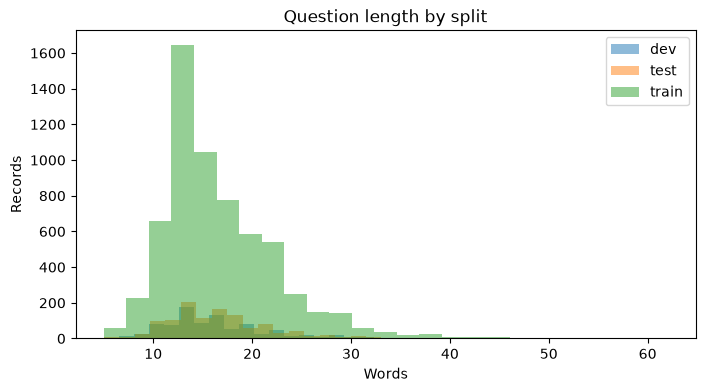

In [7]:
stop_words = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "by",
    "did",
    "do",
    "does",
    "for",
    "from",
    "how",
    "in",
    "is",
    "it",
    "of",
    "on",
    "or",
    "the",
    "to",
    "was",
    "what",
    "when",
    "which",
    "with",
    "would",
}
question_rows = []
term_counts = Counter()
for name, records in splits.items():
    for record in records:
        question = record["qa"]["question"]
        question_rows.append(
            {"split": name, "characters": len(question), "words": len(question.split())}
        )
        if name == "train":
            term_counts.update(
                token
                for token in re.findall(r"[a-z]+", question.lower())
                if token not in stop_words and len(token) > 1
            )

question_frame = pd.DataFrame(question_rows)
display(
    question_frame.groupby("split")[["characters", "words"]].agg(["min", "median", "mean", "max"])
)
display(pd.DataFrame(term_counts.most_common(20), columns=["term", "train_count"]))

fig, axis = plt.subplots(figsize=(8, 4))
for name, group in question_frame.groupby("split"):
    axis.hist(group["words"], bins=25, alpha=0.5, label=name)
axis.set(title="Question length by split", xlabel="Words", ylabel="Records")
axis.legend()
plt.show()

## Tables, text context, and numeric-looking cells

The numeric-cell check is deliberately heuristic: it identifies strings that resemble numbers, currency, percentages, negative values, or years. It does not solve semantic financial-value extraction.

,table_rows,table_columns,pre_text_lines,post_text_lines,numeric_like_cells,cells,percent_cells,currency_cells,negative_marker_cells,year_like_cells
split,,,,,,,,,,
dev,6.0,4.0,8.0,11.0,15.0,21.0,0.0,4.0,1.0,3.0
test,6.0,4.0,10.0,9.0,15.0,21.0,0.0,4.0,1.0,3.0
train,6.0,4.0,9.0,10.0,15.0,20.0,0.0,4.0,1.0,3.0


,numeric_like_cells,cells,numeric_like_percent
split,,,
dev,15843,20895,75.821967
test,21257,28085,75.688090
train,109965,147061,74.775093


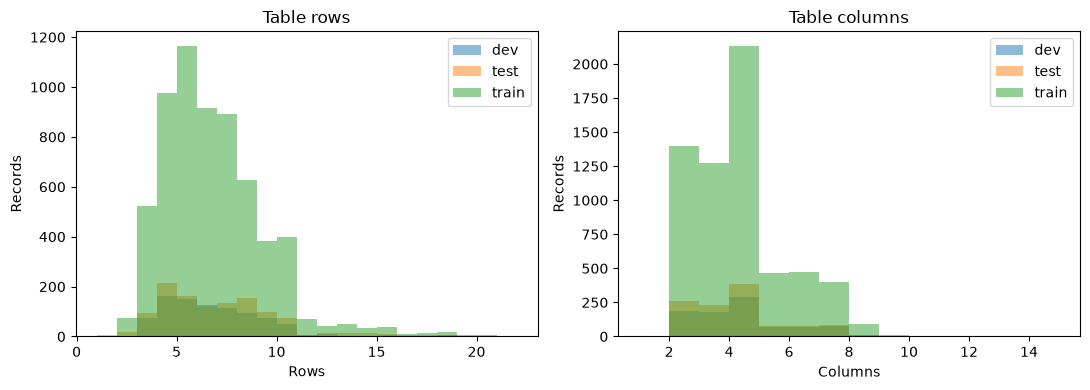

In [8]:
number_pattern = re.compile(r"(?<![\w.])-?\$?\d[\d,]*(?:\.\d+)?%?")
year_pattern = re.compile(r"\b(?:19|20)\d{2}\b")
context_rows = []
for name, records in splits.items():
    for record in records:
        table = record["table"]
        cells = [str(cell) for row in table for cell in row]
        context_rows.append(
            {
                "split": name,
                "table_rows": len(table),
                "table_columns": len(table[0]),
                "pre_text_lines": len(record["pre_text"]),
                "post_text_lines": len(record["post_text"]),
                "numeric_like_cells": sum(bool(number_pattern.search(cell)) for cell in cells),
                "cells": len(cells),
                "percent_cells": sum("%" in cell for cell in cells),
                "currency_cells": sum("$" in cell for cell in cells),
                "negative_marker_cells": sum("-" in cell for cell in cells),
                "year_like_cells": sum(bool(year_pattern.search(cell)) for cell in cells),
            }
        )

context_frame = pd.DataFrame(context_rows)
display(context_frame.groupby("split").median(numeric_only=True))
numeric_share = context_frame.groupby("split")[["numeric_like_cells", "cells"]].sum()
numeric_share["numeric_like_percent"] = (
    100 * numeric_share["numeric_like_cells"] / numeric_share["cells"]
)
display(numeric_share)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in context_frame.groupby("split"):
    axes[0].hist(group["table_rows"], bins=range(1, 23), alpha=0.5, label=name)
    axes[1].hist(group["table_columns"], bins=range(1, 16), alpha=0.5, label=name)
axes[0].set(title="Table rows", xlabel="Rows", ylabel="Records")
axes[1].set(title="Table columns", xlabel="Columns", ylabel="Records")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

## Reasoning programs and gold evidence

Operations are counted only after inspecting the program strings. Gold evidence keys are audited as annotations, not treated as model predictions. A key-position diagnostic checks whether `table_n` and `text_n` references are within the available table or concatenated text context.

In [9]:
program_rows = []
evidence_rows = []
for name, records in splits.items():
    operations = Counter()
    text_keys = table_keys = valid_text_positions = valid_table_positions = 0
    invalid_reference_keys = []
    for record in records:
        program = record["qa"]["program"]
        operation_names = operation_pattern.findall(program)
        operations.update(operation_names)
        program_rows.append(
            {
                "split": name,
                "operation_count": len(operation_names),
            }
        )
        for key in record["qa"]["gold_inds"]:
            prefix, _, suffix = key.partition("_")
            try:
                index = int(suffix)
            except ValueError:
                invalid_reference_keys.append(key)
                continue
            if prefix == "table":
                table_keys += 1
                is_valid = 0 <= index < len(record["table"])
                valid_table_positions += is_valid
            elif prefix == "text":
                text_keys += 1
                context = record["pre_text"] + record["post_text"]
                is_valid = 0 <= index < len(context)
                valid_text_positions += is_valid
            else:
                invalid_reference_keys.append(key)
                continue
            if not is_valid:
                invalid_reference_keys.append(key)
    for operation, count in operations.items():
        evidence_rows.append(
            {"split": name, "kind": "operation", "name": operation, "count": count}
        )
    evidence_rows.extend(
        [
            {"split": name, "kind": "evidence", "name": "table keys", "count": table_keys},
            {"split": name, "kind": "evidence", "name": "text keys", "count": text_keys},
            {
                "split": name,
                "kind": "evidence",
                "name": "valid table positions",
                "count": valid_table_positions,
            },
            {
                "split": name,
                "kind": "evidence",
                "name": "valid text positions",
                "count": valid_text_positions,
            },
            {
                "split": name,
                "kind": "evidence",
                "name": "invalid or unsupported keys",
                "count": len(invalid_reference_keys),
            },
        ]
    )

program_frame = pd.DataFrame(program_rows)
evidence_frame = pd.DataFrame(evidence_rows)
display(program_frame.groupby("split").agg(["min", "median", "mean", "max"]))
display(
    evidence_frame.query("kind == 'operation'")
    .pivot(index="name", columns="split", values="count")
    .fillna(0)
    .astype(int)
)
display(
    evidence_frame.query("kind == 'evidence'").pivot(index="name", columns="split", values="count")
)

operation_count                     
                  min median      mean max
split                                     
dev                 1    1.0  1.542469   5
test                1    1.0  1.544900   5
train               1    1.0  1.535434   6

split,dev,test,train
name,,,
add,180,260,1512
divide,636,820,4445
exp,1,3,5
greater,10,20,124
multiply,83,109,567
subtract,416,521,2739
table_average,19,15,95
table_max,8,10,48
table_min,5,4,27


split,dev,test,train
name,,,
invalid or unsupported keys,0,0,1
table keys,1071,1318,7512
text keys,442,585,3180
valid table positions,1071,1318,7512
valid text positions,442,585,3179


## Follow-up: field anomalies and repeated questions

This inspection reports the exact anomalous records compactly. Blank fields are evaluated alongside the executable answer, program, and raw context before deciding whether they are optional or invalid. Repeated questions are compared by filename and a raw-context signature; no split is modified.

In [10]:
from collections import defaultdict


def compact_anomalies(field, records, split_name):
    rows = []
    for record in records:
        value = record["qa"].get(field) if field in record["qa"] else record.get(field)
        if value:
            continue
        qa = record["qa"]
        rows.append(
            {
                "split": split_name,
                "id": record["id"],
                "field": field,
                "field_value": repr(value),
                "exe_ans": repr(qa["exe_ans"]),
                "program": qa["program"],
                "question": qa["question"],
                "context_preview": " ".join((record["pre_text"] + record["post_text"])[:2]),
            }
        )
    return rows


followup_splits = {name: load_finqa_split(RAW_DATA_DIR / f"{name}.json") for name in SPLIT_NAMES}

anomaly_rows = []
for split_name, records in followup_splits.items():
    for field_name in ("answer", "explanation", "table_retrieved", "text_retrieved"):
        anomaly_rows.extend(compact_anomalies(field_name, records, split_name))

anomaly_frame = pd.DataFrame(anomaly_rows)
display(anomaly_frame.groupby(["field", "split"]).size().unstack(fill_value=0))
display(anomaly_frame.query("field == 'answer'"))


def context_signature(record):
    payload = json.dumps(
        {
            "table": record["table"],
            "pre_text": record["pre_text"],
            "post_text": record["post_text"],
        },
        sort_keys=True,
    )
    return hashlib.sha256(payload.encode()).hexdigest()


overlap_rows = []
for left, right in (("train", "dev"), ("train", "test"), ("dev", "test")):
    left_by_question = defaultdict(list)
    right_by_question = defaultdict(list)
    for record in followup_splits[left]:
        left_by_question[record["qa"]["question"].strip()].append(record)
    for record in followup_splits[right]:
        right_by_question[record["qa"]["question"].strip()].append(record)
    for question in sorted(set(left_by_question) & set(right_by_question)):
        for left_record in left_by_question[question]:
            for right_record in right_by_question[question]:
                overlap_rows.append(
                    {
                        "split_pair": f"{left}/{right}",
                        "question": question,
                        "left_id": left_record["id"],
                        "right_id": right_record["id"],
                        "same_filename": left_record["filename"] == right_record["filename"],
                        "same_context": context_signature(left_record)
                        == context_signature(right_record),
                        "same_exe_ans": left_record["qa"]["exe_ans"]
                        == right_record["qa"]["exe_ans"],
                    }
                )

overlap_frame = pd.DataFrame(overlap_rows)
display(
    overlap_frame.groupby("split_pair")[["same_filename", "same_context", "same_exe_ans"]].sum()
)
display(overlap_frame)

split,dev,test,train
field,,,
answer,12,14,48
explanation,742,970,5276
table_retrieved,47,90,440
text_retrieved,101,111,620


,split,id,field,field_value,exe_ans,program,question,context_preview
0,train,ABMD/2012/page_75.pdf-1,answer,'','yes',"multiply(607, 18.13), multiply(#0, const_1000), multiply(3.3, const_1000000), greater(#1, #2)","during the 2012 year , did the equity awards in which the prescribed performance milestones were achieved exceed the...","abiomed , inc . and subsidiaries notes to consolidated financial statements 2014 ( continued ) note 8 ."
1,train,PNC/2012/page_110.pdf-3,answer,'',22929.0,"add(15553, 7376)","in millions , what is the total of home equity lines of credit?","consist of first and second liens , the charge-off amounts for the pool are proportionate to the composition of firs..."
2,train,DISCA/2013/page_45.pdf-3,answer,'',1106.45161,"subtract(51%, 20%), divide(343, #0)","as of january 21 , 2014 , what was the implied total value of eurosport international based on the price paid for th...","our international networks segment owns and operates the following television networks , which reached the following..."
3,train,C/2015/page_314.pdf-2,answer,'',-0.5425,"subtract(110.14, const_100), divide(#0, const_100), subtract(164.39, const_100), divide(#2, const_100), subtract(#1,...",what was the difference in percentage cumulative total return of citi common stock compared to the s&p financials fo...,performance graph comparison of five-year cumulative total return the following graph and table compare the cumulati...
4,train,RE/2013/page_40.pdf-2,answer,'',729.3,"subtract(1300.4, 571.1)",what was the amount of change in pre-tax catastrophe losses from 2010 to 2011 in millions,corporate income taxes other than withholding taxes on certain investment income and premium excise taxes . if group...
...,...,...,...,...,...,...,...,...
7295,test,DG/2007/page_67.pdf-2,answer,'',10.2,"add(0.2, 9.4), add(#0, 0.6)",what was the amount of the total impairment charges included in sg&a expense from 2005 to 2007 in millions,property and equipment property and equipment are recorded at cost . the company provides for depreciation and amort...
7296,test,ETR/2016/page_23.pdf-4,answer,'',5729.0,"subtract(5829, 100)",assuming there would not have been a sale of the 583 mw rhode island state energy center in 2015 . what would have n...,entergy corporation and subsidiaries management 2019s financial discussion and analysis a result of the entergy loui...
7297,test,RSG/2018/page_135.pdf-2,answer,'',-0.43333,"subtract(17, 30), divide(#0, 30)",what was the percentage decline in the equity from 2017 to 2018 actual,"republic services , inc . notes to consolidated financial statements 2014 ( continued ) we determine the discount ra..."
7298,test,DRE/2007/page_56.pdf-2,answer,'',1.56326,"divide(217692, 139255)",what is the net income per common share for the year 2007?,2007 duke realty corporation annual report54 recognition and account for the continued operations of the property by...


,same_filename,same_context,same_exe_ans
split_pair,,,
dev/test,0,0,0
train/dev,0,0,8
train/test,0,0,1


,split_pair,question,left_id,right_id,same_filename,same_context,same_exe_ans
0,train/dev,what is the combined number of equity compensation plans approved by security holders,HII/2013/page_127.pdf-3,HII/2017/page_124.pdf-4,False,False,False
1,train/dev,what is the growth rate in net revenue in 2016?,ETR/2017/page_25.pdf-3,ETR/2017/page_26.pdf-4,False,False,False
2,train/dev,what is the growth rate in net revenue in 2016?,ETR/2016/page_18.pdf-1,ETR/2017/page_26.pdf-4,False,False,True
3,train/dev,what is the growth rate in net revenue in 2016?,ETR/2016/page_17.pdf-1,ETR/2017/page_26.pdf-4,False,False,False
4,train/dev,what is the net change in net revenue during 2008?,ETR/2008/page_313.pdf-2,ETR/2008/page_355.pdf-3,False,False,False
5,train/dev,what is the net change in net revenue during 2016?,ETR/2016/page_18.pdf-2,ETR/2017/page_26.pdf-3,False,False,True
6,train/dev,what is the percent change in net revenue between 2006 and 2007?,ETR/2008/page_314.pdf-1,ETR/2008/page_377.pdf-3,False,False,False
7,train/dev,what is the percent change in net revenue between 2006 and 2007?,ETR/2008/page_267.pdf-1,ETR/2008/page_377.pdf-3,False,False,False
8,train/dev,what is the percent change in net revenue from 2015 to 2016?,ETR/2016/page_17.pdf-3,ETR/2017/page_26.pdf-1,False,False,False
9,train/dev,what is the percent change in net revenue from 2015 to 2016?,ETR/2017/page_25.pdf-1,ETR/2017/page_26.pdf-1,False,False,False


## Follow-up: evidence indexing and conservative program parsing

`text_n` is checked against zero-based `pre_text + post_text`; `table_n` against zero-based table rows. The parser below only validates syntax and tokens—it never executes a program or uses `eval`. Unsupported syntax is reported for later, test-driven extension.

**Re-execution note (2026-10-22).** This notebook was re-executed with the current package parser, which was extended in Notebook 04 to cover every observed program form. It now parses all 6,251/883/1,147 programs. The first execution (2026-10-20) used the narrower original grammar and parsed 6,029/840/1,107; those counts and the unsupported forms they revealed are recorded in `docs/m2-data-findings.md`. All other outputs of this notebook are unchanged by the re-execution.

In [11]:
from finevidence.data import parse_finqa_program, validate_evidence_key

validation_splits = {name: load_finqa_split(RAW_DATA_DIR / f"{name}.json") for name in SPLIT_NAMES}

validation_rows = []
failure_rows = []
for split_name, records in validation_splits.items():
    valid_programs = invalid_programs = valid_evidence = invalid_evidence = 0
    for record in records:
        program_result = parse_finqa_program(record["qa"]["program"])
        if program_result.is_valid:
            valid_programs += 1
        else:
            invalid_programs += 1
            if (
                len(
                    [
                        row
                        for row in failure_rows
                        if row["kind"] == "program" and row["split"] == split_name
                    ]
                )
                < 3
            ):
                failure_rows.append(
                    {
                        "split": split_name,
                        "kind": "program",
                        "id": record["id"],
                        "raw_value": record["qa"]["program"],
                        "reason": program_result.error,
                    }
                )
        for raw_key, raw_value in record["qa"]["gold_inds"].items():
            evidence_result = validate_evidence_key(
                raw_key,
                text_count=len(record["pre_text"]) + len(record["post_text"]),
                table_count=len(record["table"]),
            )
            if evidence_result.is_valid:
                valid_evidence += 1
            else:
                invalid_evidence += 1
                failure_rows.append(
                    {
                        "split": split_name,
                        "kind": "evidence",
                        "id": record["id"],
                        "raw_value": f"{raw_key}: {raw_value}",
                        "reason": evidence_result.reason,
                    }
                )
    validation_rows.append(
        {
            "split": split_name,
            "valid_programs": valid_programs,
            "unsupported_programs": invalid_programs,
            "valid_evidence_keys": valid_evidence,
            "invalid_evidence_keys": invalid_evidence,
        }
    )

display(pd.DataFrame(validation_rows).set_index("split"))
display(pd.DataFrame(failure_rows))

,valid_programs,unsupported_programs,valid_evidence_keys,invalid_evidence_keys
split,,,,
train,6251,0,10691,1
dev,883,0,1513,0
test,1147,0,1903,0


,split,kind,id,raw_value,reason
0,train,evidence,RE/2010/page_120.pdf-2,text_-1: this guidance had no impact on how the company records its derivatives. .,index outside source bounds


## Evidence-based preprocessing plan

The table below converts observed audit evidence into proposed M3-ready preprocessing work. These are decisions to implement and validate in Notebook 03; they do not alter the raw files or official split assignments.

In [12]:
shared_questions = {
    pair: len(
        {r["qa"]["question"].strip() for r in splits[pair[0]]}
        & {r["qa"]["question"].strip() for r in splits[pair[1]]}
    )
    for pair in (("train", "dev"), ("train", "test"), ("dev", "test"))
}
summary = pd.DataFrame(
    [
        {
            "observation": "Schema consistency",
            "measured evidence": "Top-level and qa key sets are identical across splits.",
            "project impact": "One loader and one schema validator can serve all public splits.",
            "proposed action": "Implement an explicit field-level validator without hard-coding inferred semantics.",
        },
        {
            "observation": "Question overlap",
            "measured evidence": str(shared_questions),
            "project impact": "Repeated question strings are a split diagnostic, not proof of leakage.",
            "proposed action": "Preserve official splits and log overlap checks before every comparison.",
        },
        {
            "observation": "Evidence references",
            "measured evidence": "Gold evidence uses text_n and table_n keys; position checks are reported above.",
            "project impact": "Evidence normalization needs source-aware mapping and anomaly handling.",
            "proposed action": "Preserve raw keys; validate ranges and flag rather than discard invalid references.",
        },
        {
            "observation": "Numeric table surface",
            "measured evidence": "The numeric-like cell share is shown above by split.",
            "project impact": "Numeric normalization must retain currencies, percentages, negatives, units, and periods.",
            "proposed action": "Create reversible value parsing with raw-cell retention and unit/period tests.",
        },
        {
            "observation": "Reasoning programs",
            "measured evidence": "Observed operation counts and program lengths are reported above.",
            "project impact": "A parser should start from the observed grammar and expose parse failures.",
            "proposed action": "Implement a conservative program tokenizer before any execution logic.",
        },
    ]
)
display(summary)

,observation,measured evidence,project impact,proposed action
0,Schema consistency,Top-level and qa key sets are identical across splits.,One loader and one schema validator can serve all public splits.,Implement an explicit field-level validator without hard-coding inferred semantics.
1,Question overlap,"{('train', 'dev'): 16, ('train', 'test'): 7, ('dev', 'test'): 2}","Repeated question strings are a split diagnostic, not proof of leakage.",Preserve official splits and log overlap checks before every comparison.
2,Evidence references,Gold evidence uses text_n and table_n keys; position checks are reported above.,Evidence normalization needs source-aware mapping and anomaly handling.,Preserve raw keys; validate ranges and flag rather than discard invalid references.
3,Numeric table surface,The numeric-like cell share is shown above by split.,"Numeric normalization must retain currencies, percentages, negatives, units, and periods.",Create reversible value parsing with raw-cell retention and unit/period tests.
4,Reasoning programs,Observed operation counts and program lengths are reported above.,A parser should start from the observed grammar and expose parse failures.,Implement a conservative program tokenizer before any execution logic.


## Experiment-input boundary

"
    "For an answer-prediction experiment, use only the question plus financial context: "
    "`table`, `pre_text`, and `post_text` (or a documented derived representation). "
    "Do **not** use `answer`, `exe_ans`, `program`, `program_re`, `gold_inds`, `steps`, "
    "`ann_table_rows`, `ann_text_rows`, or other answer/evidence annotations as model input features. "
    "Those fields are supervision, analysis, or evaluation information depending on the experiment. "
    "This rule prevents label and evidence leakage.

"
    "The field contract and next preprocessing decisions are documented in "
    "`docs/preprocessing-plan.md`.

## Recommendation for Notebook 03

Create `03_data_preprocessing.ipynb` to turn the evidence above into tested, reversible preprocessing: split loading and validation, context and evidence-reference normalization, raw-cell-preserving numeric parsing, and conservative program tokenization. Keep all transformations separate from the raw official files and evaluate fit-dependent choices using training data only.